# 04 · LightGBM, SHAP and temperature scenarios

The main model. Features come from `mart.features_hourly`: lags and rolling windows that stop 24+ hours back, calendar, holiday flag and temperature.

Protocol: tune a small grid on the **validation year**; keep the best setting; score validation with the train-only model, then refit on train + validation (same settings, ~10% more trees) for the **test** period. Test is never used to choose anything.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))   # so "from src..." works from the notebooks folder


In [2]:
import json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import shap
from src.config import SCENARIO_OFFSETS
from src.features import load_features, add_groups, assign_split
from src.evaluate import summarize, error_by
from src.train import FEATURES, GRID, tune, fit_fixed, make_xy, shift_temperature
from src.write_forecasts import write_forecasts, write_scenarios

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})
FIG = ROOT / "docs" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
RES = ROOT / "docs" / "results"; RES.mkdir(parents=True, exist_ok=True)

df = assign_split(add_groups(load_features()))
train, valid, test = (df[df["split"] == s] for s in ["train", "validation", "test"])
print(len(train), len(valid), len(test), "rows | features:", len(FEATURES))

122520 8784 13897 rows | features: 19


## 1 · Tune on the validation year

Eight combinations (leaves, minimum leaf size, squared vs absolute-error objective), each trained with early stopping on the validation year. Takes a few minutes.

In [3]:
grid = tune(train, valid)
grid.round(3)

e:\energy-demand-forecasting\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
e:\energy-demand-forecasting\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
e:\energy-demand-forecasting\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
e:\energy-demand-forecasting\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_

,num_leaves,min_child_samples,objective,best_iteration,valid_WAPE_%,valid_RMSE_MW
0,31,100,regression_l1,1520,2.750,1156.514
1,31,20,regression_l1,1965,2.752,1155.304
2,127,20,regression_l1,997,2.762,1158.893
3,127,100,regression_l1,1094,2.772,1165.591
4,127,20,regression,468,2.773,1169.452
5,31,100,regression,834,2.775,1163.075
6,31,20,regression,875,2.785,1161.822
7,127,100,regression,339,2.785,1174.709


In [4]:
best = grid.iloc[0]
params = {"num_leaves": int(best["num_leaves"]), "min_child_samples": int(best["min_child_samples"]),
          "objective": str(best["objective"])}
n_val = int(best["best_iteration"])
n_final = int(round(n_val * 1.1))
print("best:", params, "| trees:", n_val, "-> final:", n_final)
json.dump({**params, "n_estimators": n_val}, open(RES / "lightgbm_best_params.json", "w"))

best: {'num_leaves': 31, 'min_child_samples': 100, 'objective': 'regression_l1'} | trees: 1520 -> final: 1672


## 2 · Fit and forecast

In [5]:
model_val = fit_fixed(train, params, n_val)                              # train only -> validation forecasts
model_final = fit_fixed(pd.concat([train, valid]), params, n_final)       # train + validation -> test forecasts

ev = df[df["split"].isin(["validation", "test"])].copy()
ev["lightgbm_mw"] = np.where(ev["split"] == "validation",
                             model_val.predict(make_xy(ev)[0]),
                             model_final.predict(make_xy(ev)[0]))
ev["baseline_mw"] = ev["load_lag_168h"]
ev["yesterday_mw"] = ev["load_lag_24h"]

summary = pd.concat([
    summarize(ev, "baseline_mw", "seasonal_naive"),
    summarize(ev, "yesterday_mw", "same_hour_yesterday (benchmark)"),
    summarize(ev, "lightgbm_mw", "lightgbm"),
])
summary.round(2)

,model,split,MAPE_%,WAPE_%,RMSE_MW,MAE_MW,bias_MW,n_hours,peak_MAE_MW,peak_bias_MW,peak_MAPE_%,peak_hour_within_1h_%,n_days
0,seasonal_naive,validation,10.24,10.60,4602.00,3323.27,-60.90,8783,4033.88,-60.16,10.55,73.70,365
1,seasonal_naive,test,10.99,11.30,4794.30,3511.52,-66.97,13895,4388.97,-111.60,11.80,64.53,578
0,same_hour_yesterday (benchmark),validation,6.57,6.65,2863.92,2084.36,-8.43,8783,2268.43,-1.81,6.13,71.78,365
1,same_hour_yesterday (benchmark),test,7.32,7.40,3134.38,2300.29,-14.98,13895,2618.00,-19.46,7.18,66.09,578
0,lightgbm,validation,2.71,2.75,1156.51,861.75,413.29,8783,866.89,447.16,2.34,78.90,365
1,lightgbm,test,3.16,3.19,1294.05,991.36,396.72,13895,1126.09,503.46,3.08,76.12,578


In [6]:
wape = summary.pivot(index="model", columns="split", values="WAPE_%")
wape["test_vs_seasonal_naive_%"] = (1 - wape["test"] / wape.loc["seasonal_naive", "test"]) * 100
wape["test_vs_yesterday_%"] = (1 - wape["test"] / wape.loc["same_hour_yesterday (benchmark)", "test"]) * 100
wape.round(2)

split,test,validation,test_vs_seasonal_naive_%,test_vs_yesterday_%
model,,,,
lightgbm,3.19,2.75,71.77,56.90
same_hour_yesterday (benchmark),7.40,6.65,34.49,0.00
seasonal_naive,11.30,10.60,0.00,-52.66


## 3 · Where does it do well or badly?

,WAPE_%,MAE_MW,bias_MW,n_hours
day_type,,,,
holiday,3.58,1100.62,175.07,672
weekday,2.98,953.03,476.11,15601
weekend,3.06,895.53,249.31,6405


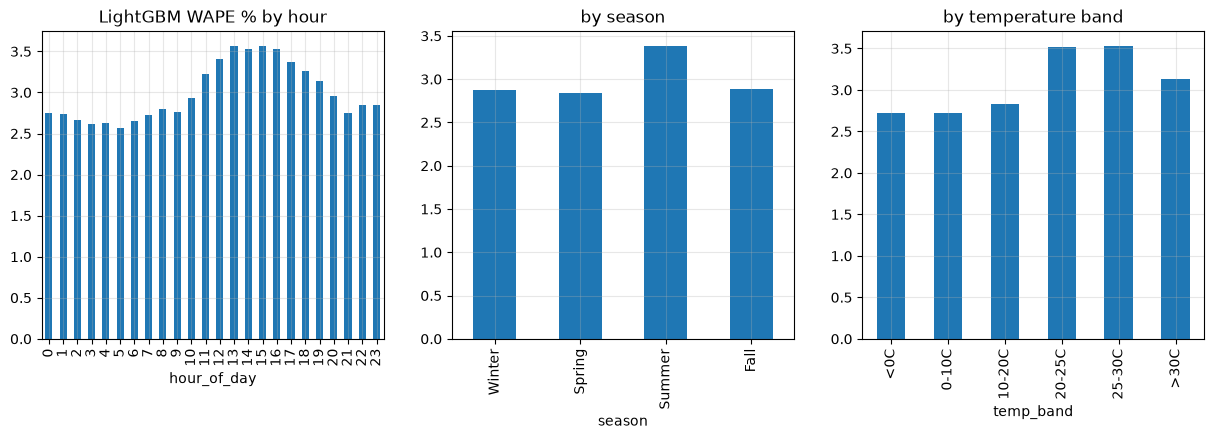

In [7]:
ev["forecast_mw"] = ev["lightgbm_mw"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
error_by(ev, "hour_of_day")["WAPE_%"].plot.bar(ax=axes[0], title="LightGBM WAPE % by hour")
error_by(ev, "season")["WAPE_%"].reindex(["Winter", "Spring", "Summer", "Fall"]).plot.bar(ax=axes[1], title="by season")
error_by(ev, "temp_band")["WAPE_%"].plot.bar(ax=axes[2], title="by temperature band")
fig.savefig(FIG / "lightgbm_error_breakdown.png", dpi=150, bbox_inches="tight")
error_by(ev, "day_type").round(2)

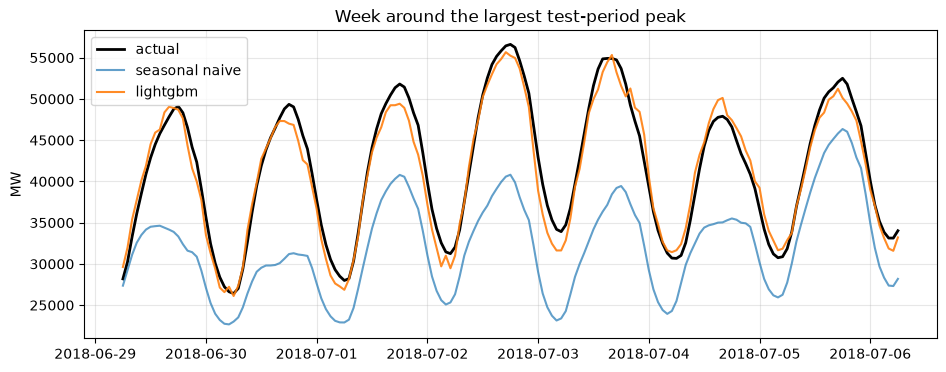

In [8]:
centre = ev[ev["split"] == "test"]["load_mw"].idxmax()
week = ev.loc[centre - 84: centre + 84]
fig, ax = plt.subplots()
ax.plot(week["ts"], week["load_mw"], label="actual", lw=2, color="black")
ax.plot(week["ts"], week["baseline_mw"], label="seasonal naive", alpha=0.7)
ax.plot(week["ts"], week["lightgbm_mw"], label="lightgbm", alpha=0.9)
ax.set(title="Week around the largest test-period peak", ylabel="MW"); ax.legend()
fig.savefig(FIG / "lightgbm_week_around_peak.png", dpi=150, bbox_inches="tight")

## 4 · SHAP: which features drive the forecasts?

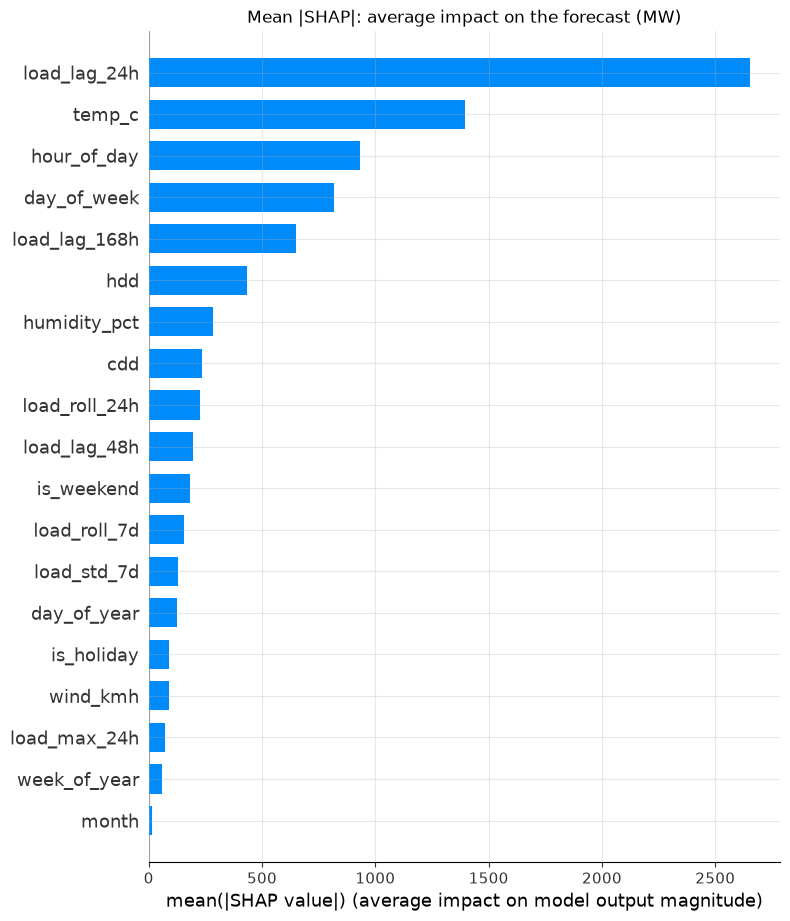

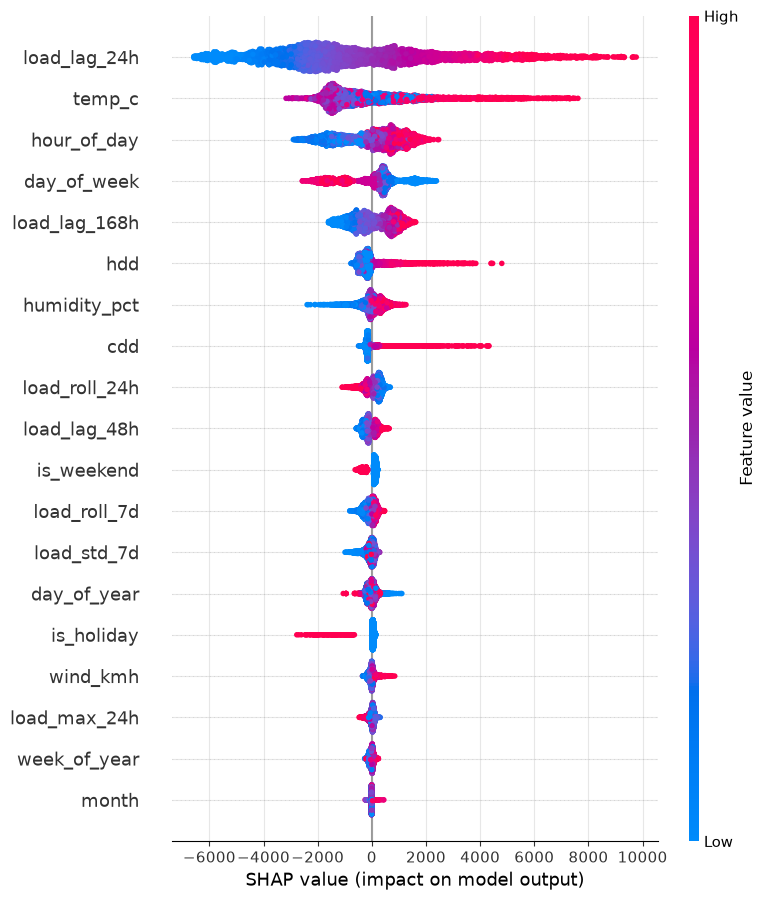

In [9]:
rng = np.random.default_rng(0)
X_test, _ = make_xy(test)
sample = X_test.iloc[rng.choice(len(X_test), size=min(5000, len(X_test)), replace=False)]
explainer = shap.TreeExplainer(model_final)
sv = explainer.shap_values(sample)

plt.figure(); shap.summary_plot(sv, sample, plot_type="bar", show=False)
plt.title("Mean |SHAP|: average impact on the forecast (MW)")
plt.savefig(FIG / "shap_importance.png", dpi=150, bbox_inches="tight"); plt.show()

plt.figure(); shap.summary_plot(sv, sample, show=False)
plt.savefig(FIG / "shap_beeswarm.png", dpi=150, bbox_inches="tight"); plt.show()

<Figure size 1100x400 with 0 Axes>

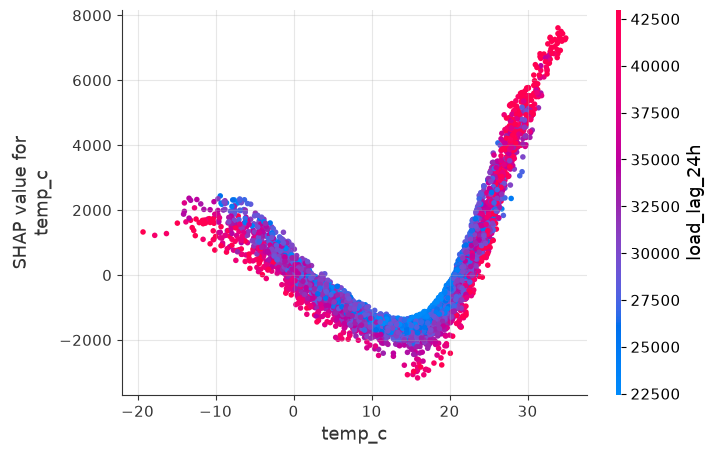

hot rows: 106, cold rows: 578 (mean |SHAP| in MW)


,all hours,hot (>30C),cold (<0C)
load_lag_24h,2653.0,6239.0,2317.0
temp_c,1396.0,6058.0,938.0
hour_of_day,934.0,500.0,1142.0
day_of_week,820.0,1050.0,793.0
load_lag_168h,650.0,990.0,611.0
hdd,434.0,185.0,1522.0
humidity_pct,285.0,657.0,117.0
cdd,233.0,2508.0,172.0
load_roll_24h,228.0,306.0,252.0
load_lag_48h,195.0,292.0,191.0


In [10]:
plt.figure(); shap.dependence_plot("temp_c", sv, sample, show=False)
plt.savefig(FIG / "shap_temperature.png", dpi=150, bbox_inches="tight"); plt.show()

imp = pd.DataFrame(np.abs(sv), columns=sample.columns)
extremes = pd.DataFrame({
    "all hours": imp.mean(),
    "hot (>30C)": imp[sample["temp_c"].values > 30].mean(),
    "cold (<0C)": imp[sample["temp_c"].values < 0].mean(),
}).sort_values("all hours", ascending=False).round(0)
print(f"hot rows: {(sample['temp_c'] > 30).sum()}, cold rows: {(sample['temp_c'] < 0).sum()} (mean |SHAP| in MW)")
extremes

## 5 · Temperature what-if scenarios (for the Power BI scenario page)

Shift the observed temperature by -5 to +5 C and re-score the test period. Only the temperature inputs move; the lag features still contain the real past weather, so this is a *conservative* what-if (the true effect of a sustained heat wave would be larger).

In [11]:
frames = []
for off in SCENARIO_OFFSETS:
    shifted = shift_temperature(test, offset_c=off)
    frames.append(pd.DataFrame({"ts": test["ts"].values, "temp_offset_c": off,
                                "forecast_mw": model_final.predict(make_xy(shifted)[0])}))
scen = pd.concat(frames, ignore_index=True)

daily_peak = scen.assign(date=scen["ts"].dt.normalize()).groupby(["temp_offset_c", "date"])["forecast_mw"].max()
tbl = pd.DataFrame({"avg_forecast_MW": scen.groupby("temp_offset_c")["forecast_mw"].mean(),
                    "avg_daily_peak_MW": daily_peak.groupby("temp_offset_c").mean()}).round(0)
tbl["avg_change_vs_0C_MW"] = tbl["avg_forecast_MW"] - tbl.loc[0, "avg_forecast_MW"]
tbl

,avg_forecast_MW,avg_daily_peak_MW,avg_change_vs_0C_MW
temp_offset_c,,,
-5,30985.0,35582.0,-481.0
-4,30988.0,35714.0,-478.0
-3,31042.0,35905.0,-424.0
-2,31142.0,36143.0,-324.0
-1,31284.0,36414.0,-182.0
0,31466.0,36727.0,0.0
1,31682.0,37077.0,216.0
2,31928.0,37441.0,462.0
3,32199.0,37797.0,733.0


In [12]:
n = write_scenarios(scen, "lightgbm")
print(f"wrote {n:,} rows to mart.fact_forecast_scenario")

wrote 152,867 rows to mart.fact_forecast_scenario


## 6 · How much does forecast-temperature error hurt?

Real day-ahead systems use a weather *forecast*, not the observed temperature. Add random noise to the test temperatures to see how fast accuracy degrades.

In [13]:
rows = []
for sd in [0, 1, 2, 3]:
    noisy = shift_temperature(test, noise_sd_c=sd, seed=1)
    t = test.assign(noisy_mw=model_final.predict(make_xy(noisy)[0]))
    s = summarize(t.assign(split="test"), "noisy_mw", f"noise sd {sd}C", splits=["test"])
    rows.append(s)
noise = pd.concat(rows)[["model", "WAPE_%", "RMSE_MW", "peak_MAE_MW", "peak_hour_within_1h_%"]].round(2)
noise.to_csv(RES / "temperature_noise_sensitivity.csv", index=False)
noise

,model,WAPE_%,RMSE_MW,peak_MAE_MW,peak_hour_within_1h_%
0,noise sd 0C,3.19,1294.05,1126.09,76.12
0,noise sd 1C,3.52,1450.72,1356.27,68.69
0,noise sd 2C,4.31,1829.11,1921.26,60.73
0,noise sd 3C,5.27,2285.03,2679.70,54.33


## 7 · Save forecasts and metrics

In [14]:
n = write_forecasts(ev, "lightgbm")
print(f"wrote {n:,} rows to mart.fact_forecast")
summary.to_csv(RES / "lightgbm_metrics.csv", index=False)

wrote 22,681 rows to mart.fact_forecast
